In [1]:
import xarray as xr

whacs_ds = (
    xr.open_zarr("inputs/WHACS/processed/WHACS_NorthCarolina.zarr")
    .sel(time="1986-01")
    .load()
)
whacs_ds

<xarray.Dataset> Size: 3MB
Dimensions:                      (time: 744, goal: 14)
Coordinates:
  * time                         (time) datetime64[ns] 6kB 1986-01-01 ... 198...
  * goal                         (goal) int64 112B 1 2 3 4 5 ... 10 11 12 13 14
    latitude                     (goal) float32 56B 36.56 36.12 ... 33.0 32.88
    longitude                    (goal) float32 56B -75.5 -75.25 ... -79.0
    seapoint                     (goal) int32 56B 1904482 1904397 ... 1903044
Data variables: (12/39)
    cge                          (time, goal) float64 83kB 2.7 3.3 ... 0.8 0.7
    dir                          (time, goal) float64 83kB 173.5 181.7 ... 83.2
    dp                           (time, goal) float64 83kB 173.0 181.0 ... 103.0
    fp                           (time, goal) float64 83kB 0.228 0.217 ... 0.095
    hs                           (time, goal) float64 83kB 1.042 1.152 ... 0.438
    pdir0                        (time, goal) float64 83kB 183.6 192.0 ... 68.5
    ...                           ...
    ptp3                         (time, goal) float64 83kB nan 10.21 ... 7.55
    spr                          (time, goal) float64 83kB 37.0 37.3 ... 25.6
    t01                          (time, goal) float64 83kB 3.88 4.06 ... 4.82
    t02                          (time, goal) float64 83kB 3.47 3.64 ... 3.96
    uwnd                         (time, goal) float64 83kB 4.4 4.5 ... -3.2 -3.3
    vwnd                         (time, goal) float64 83kB 7.2 7.5 ... 0.5 0.7
Attributes: (12/59)
    Conventions:                     CF-1.11 ACDD-1.3
    title:                           Wave Hindcast for the Australian Climate...
    summary:                         Wave Hindcast for the Australian Climate...
    keywords:                        WHACS, ACS, waves, ocean, coast, WWIII, ...
    id:                              BoM-CSIRO-WHACS-001
    naming_authority:                au.csiro
    ...                              ...
    geospatial_lon_max:              179.9375
    geospatial_vertical_positive:    up
    time_coverage_start:             1979-01-01T00:00:00
    time_coverage_end:               1979-01-31T23:00:00
    time_coverage_duration:          P30DT23H0M0S
    time_coverage_resolution:        P0DT1H0M0S

In [2]:
import pandas as pd

metamodel_parameters = {
    "hs_goals": [
        whacs_ds.hs.isel(time=itime).values.tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "tp_goals": [
        (1.0 / whacs_ds.fp.isel(time=itime).values).tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "wd_goals": [
        whacs_ds.dir.isel(time=itime).values.tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "ds_goals": [
        whacs_ds.spr.isel(time=itime).values.tolist()
        for itime in range(len(whacs_ds.time))
    ],
    "tref": pd.to_datetime(whacs_ds.time.values).strftime("%Y%m%d %H%M%S").tolist(),
}
metamodel_parameters.keys()

dict_keys(['hs_goals', 'tp_goals', 'wd_goals', 'ds_goals', 'tref'])

In [3]:
from utils.config import GOALS
from utils.snapwave_wrapper import SnapWaveDynamicModelWrapper

snapwave_wrapper = SnapWaveDynamicModelWrapper(
    templates_dir="templates-dynamic",
    metamodel_parameters=metamodel_parameters,
    fixed_parameters={},
    output_dir="SnapWave_CASES_Dynamic",
    aoi_file="inputs/AoI_Polygons/AoI_NorthCarolina.shp",
    goals_config=GOALS,
)
snapwave_wrapper

2026-06-16 23:01:04,406 - SnapWaveDynamicModelWrapper - WARNING - Parameter hs_goals is not in the default_parameters
2026-06-16 23:01:04,407 - SnapWaveDynamicModelWrapper - WARNING - Parameter tp_goals is not in the default_parameters
2026-06-16 23:01:04,407 - SnapWaveDynamicModelWrapper - WARNING - Parameter wd_goals is not in the default_parameters
2026-06-16 23:01:04,407 - SnapWaveDynamicModelWrapper - WARNING - Parameter ds_goals is not in the default_parameters
2026-06-16 23:01:04,408 - SnapWaveDynamicModelWrapper - WARNING - Parameter tref is not in the default_parameters


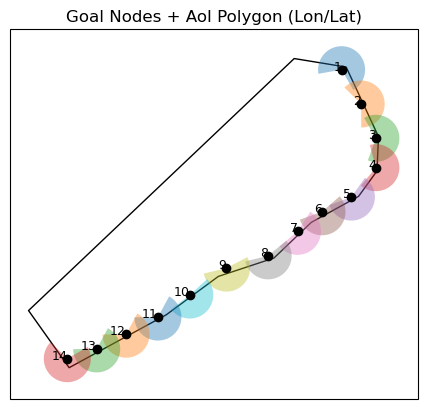

In [4]:
snapwave_wrapper.plot_configuration()

In [5]:
snapwave_wrapper.load_cases(cases_name_format=lambda ctx: f"{ctx.get('tref')}")

In [6]:
# snapwave_wrapper.run_cases_in_background(launcher="default", num_workers=2)

In [7]:
snapwave_wrapper.monitor_cases(value_counts="simple")

Status  
FINISHED    744
Name: count, dtype: int64

In [8]:
result = snapwave_wrapper.postprocess_cases()
result

<xarray.Dataset> Size: 4MB
Dimensions:         (time: 744, stations: 216)
Coordinates:
  * time            (time) datetime64[ns] 6kB 1986-01-01 ... 1986-01-31T23:00:00
    station_name    (stations) object 2kB '5m_10' '5m_11' ... 'buoy_8658120'
    station_x       (stations) float32 864B -75.86 -75.8 ... -79.19 -77.95
    station_y       (stations) float32 864B 36.51 36.32 36.14 ... 33.35 34.23
    point_zb        (stations) float32 864B nan nan nan nan ... nan nan nan nan
    station_source  (stations) object 2kB 'isobath' 'isobath' ... 'buoy' 'buoy'
    station_label   (stations) object 2kB '5m' '5m' '5m' ... 'levels' 'levels'
    station_depth   (stations) float64 2kB -5.0 -5.0 -5.0 -5.0 ... nan nan nan
Dimensions without coordinates: stations
Data variables:
    point_zs        (time, stations) float32 643kB 0.0 0.0 0.1483 ... 0.0 0.9219
    point_hm0       (time, stations) float32 643kB 0.9284 1.0 ... 0.0 0.5343
    point_tp        (time, stations) float32 643kB 4.396 4.396 ... 0.0 10.04
    point_wavdir    (time, stations) float32 643kB 186.6 191.2 ... 270.0 62.94
    point_dw        (time, stations) float32 643kB 57.64 135.9 86.28 ... 0.0 0.0
    point_df        (time, stations) float32 643kB 0.6998 1.947 ... 0.0 0.01454
Attributes:
    Conventions:                         Conventions = 'CF-1.6, SGRID-0.3
    Build-Revision-Date-Netcdf-library:  4.9.2 of Mar 31 2024 08:09:36 $
    Producer:                            SnapWave
    title:                               Snapwave his point netcdf output

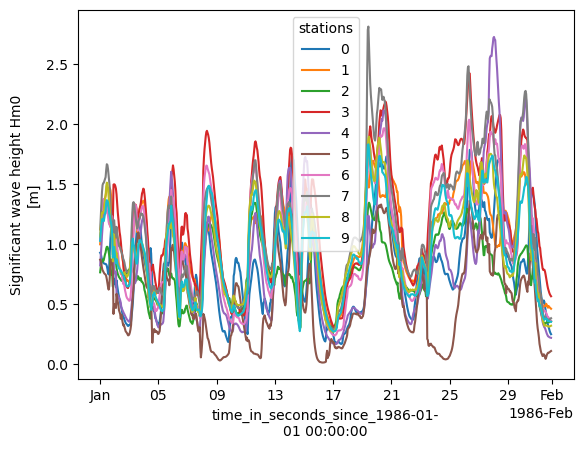

In [9]:
result.point_hm0.isel(stations=slice(None, None, 22)).plot(hue="stations");

In [10]:
result.to_netcdf("SnapWave_CASES_Dynamic/Dynamic_Cases_198601.nc")